<a href="https://colab.research.google.com/github/zskk1/exercism-solutions/blob/main/1_intro.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from fastai.vision.all import *

In [2]:
# fast.ai datasets collection
path = untar_data(URLs.PETS)/'images'
# 7390 pictures, 37 breeds

In [3]:
# labels cats
def is_cat(x): return x[0].isupper()

In [4]:
# dataset structure
dls = ImageDataLoaders.from_name_func(
    path, get_image_files(path), valid_pct=0.2, seed=42, label_func=is_cat, item_tfms=Resize(224)
)
# Transform: item_tfms or batch_tfms
# valid_pct=0.2: hold out 20% of the data (validation set)

In [5]:
learn = vision_learner(dls, resnet34, metrics=error_rate)
# cnn

In [6]:
learn.fine_tune(1)

epoch,train_loss,valid_loss,error_rate,time
0,0.163898,0.021593,0.006089,00:42


epoch,train_loss,valid_loss,error_rate,time
0,0.058760,0.021106,0.007442,00:40


In [7]:
import ipywidgets as widgets

uploader = widgets.FileUpload()
uploader

FileUpload(value={}, description='Upload')

In [8]:
img = PILImage.create(uploader.data[0])

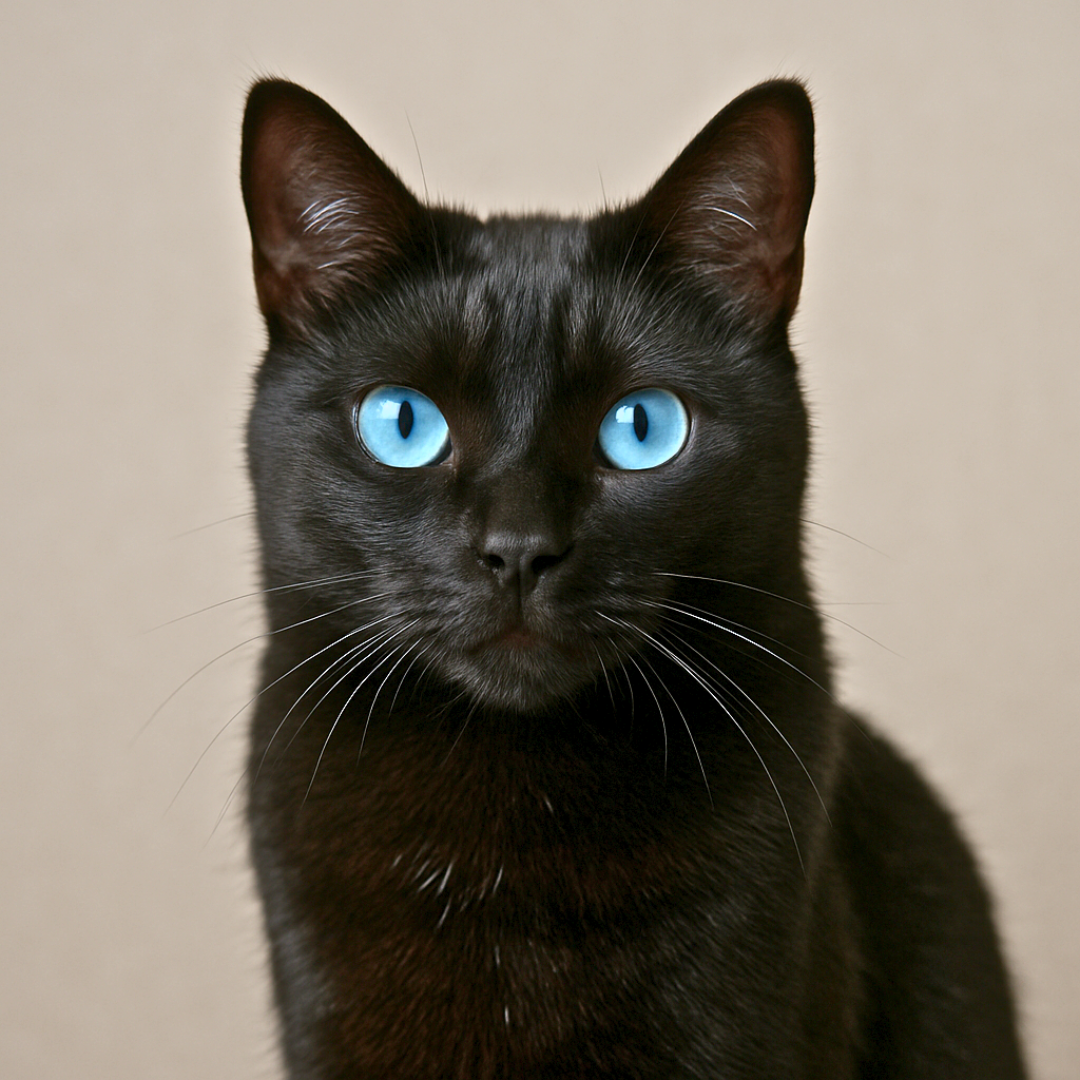

In [9]:
img

In [10]:
is_cat,_,probs = learn.predict(img)
print(f"Is this a cat?: {is_cat}.")
print(f"Probability it's a cat: {probs[1].item():.6f}")

Is this a cat?: True.
Probability it's a cat: 1.000000


In [11]:
path = untar_data(URLs.CAMVID_TINY)
dls = SegmentationDataLoaders.from_label_func(
    path, bs=8, fnames = get_image_files(path/"images"),
    label_func = lambda o: path/'labels'/f'{o.stem}_P{o.suffix}',
    codes = np.loadtxt(path/'codes.txt', dtype=str)
)

learn = unet_learner(dls, resnet34)
learn.fine_tune(8)

epoch,train_loss,valid_loss,time
0,2.733463,2.126889,00:01


epoch,train_loss,valid_loss,time
0,1.713181,1.376523,00:02
1,1.502008,1.256763,00:01
2,1.361289,1.091270,00:01
3,1.226159,0.832234,00:01
4,1.095496,0.707309,00:01
5,0.988626,0.676467,00:01
6,0.902486,0.653673,00:01
7,0.835107,0.648033,00:01


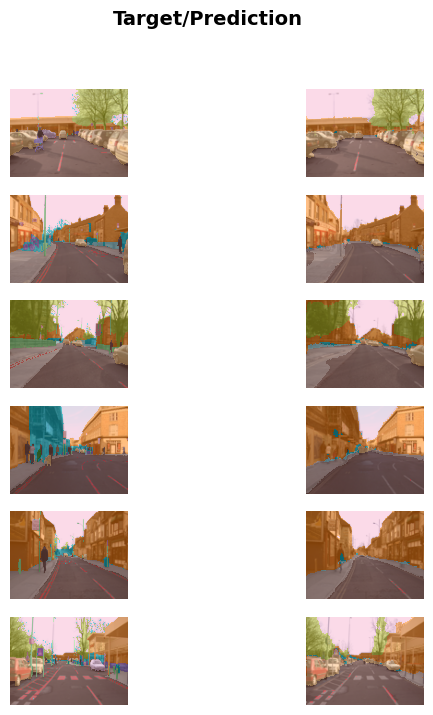

In [12]:
learn.show_results(max_n=6, figsize=(7,8))

In [13]:
# NLP
# IMDB Large Movie Review Dataset
# Learning Word Vectors for Sentiment Analysis
from fastai.text.all import *

dls = TextDataLoaders.from_folder(untar_data(URLs.IMDB), valid='test')
learn = text_classifier_learner(dls, AWD_LSTM, drop_mult=0.5, metrics=accuracy)
learn.fine_tune(4, 1e-2)

<div><progress max="105067061" value="105070592"></progress> 100.00% [105070592/105067061 00:02&lt;00:00]</div>

epoch,train_loss,valid_loss,accuracy,time
0,0.474216,0.387271,0.826840,03:23


epoch,train_loss,valid_loss,accuracy,time
0,0.314324,0.248084,0.899560,07:08
1,0.240347,0.217939,0.912520,07:08
2,0.205697,0.184324,0.929440,07:08
3,0.155111,0.184620,0.929880,07:08


In [14]:
learn.predict("I really liked that movie!")

('pos', tensor(1), tensor([0.0035, 0.9965]))

In [15]:
doc(learn.predict)

Learner.predict(item, rm_type_tfms=None, with_input=False)
Prediction on `item`, fully decoded, loss function decoded and probabilities

To get a prettier result with hyperlinks to source code and documentation, install nbdev: pip install nbdev


In [16]:
# whether a person is a high-income earner, based on their socioeconomic background
from fastai.tabular.all import *
path = untar_data(URLs.ADULT_SAMPLE)

dls = TabularDataLoaders.from_csv(path/'adult.csv', path=path, y_names="salary",
    cat_names = ['workclass', 'education', 'marital-status', 'occupation',
                 'relationship', 'race'], # categorical
    cont_names = ['age', 'fnlwgt', 'education-num'], # continuous
    procs = [Categorify, FillMissing, Normalize])

learn = tabular_learner(dls, metrics=accuracy)
# Adult Dataset - Scaling Up the Accuracy of Naive-Bayes Classifiers: a Decision-Tree Hybrid

<div><progress max="968212" value="974848"></progress> 100.69% [974848/968212 00:00&lt;00:00]</div>

In [17]:
learn.fit_one_cycle(3)

epoch,train_loss,valid_loss,accuracy,time
0,0.386027,0.357986,0.833692,00:04
1,0.359344,0.351883,0.835534,00:04
2,0.349749,0.345108,0.838759,00:04


In [18]:
# Recommendation Systems
# MovieLens Dataset
from fastai.collab import *
path = untar_data(URLs.ML_SAMPLE)
dls = CollabDataLoaders.from_csv(path/'ratings.csv')
learn = collab_learner(dls, y_range=(0.5,5.5)) # 0.6 avg err
learn.fine_tune(10)
# Sometimes it's best to experiment with fine_tune versus fit_one_cycle to see which works best for your dataset.

<div><progress max="51790" value="57344"></progress> 110.72% [57344/51790 00:00&lt;00:00]</div>

epoch,train_loss,valid_loss,time
0,1.483969,1.439152,00:00


epoch,train_loss,valid_loss,time
0,1.367950,1.381837,00:00
1,1.271086,1.210804,00:00
2,1.024790,0.913268,00:00
3,0.803878,0.757078,00:00
4,0.688114,0.711440,00:00
5,0.633793,0.700271,00:00
6,0.615053,0.695975,00:00
7,0.595605,0.691830,00:00
8,0.602130,0.689670,00:00
9,0.610273,0.689447,00:00


In [19]:
learn.show_results() # view a few examples

,userId,movieId,rating,rating_pred
0,95.0,79.0,5.0,4.000747
1,48.0,60.0,5.0,4.218986
2,6.0,12.0,3.5,2.843133
3,36.0,23.0,2.0,3.185571
4,14.0,40.0,3.5,3.248795
5,85.0,14.0,4.5,4.912095
6,53.0,6.0,5.0,4.480958
7,3.0,62.0,4.0,4.040504
8,7.0,83.0,4.0,4.152798
